# Week 8-I: Measured ablations

This notebook uses the completed 342-query W8-H run and real saved counterfactual promotion answers. It evaluates the frozen controller, removes gate/HELP/HURT filters one at a time, and compares always-promote, rank-5, seeded random, and semantic selection. Matched G0/G1 and all three revision adapters are reported separately.

Replays use measured original-SARA G0 answers; they do not claim new online timing. Removing a safety filter is not a retraining ablation. DAFiR-2 and QCLA/controller stacking remain unsupported and have no invented scores. No coefficients, checkpoint or winner are selected here. INTERNAL-VAL was previously inspected; TEST is unused. This stage needs no GPU generation.

In [1]:
import sys, subprocess, json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs/week8/w8_dafir.yaml').is_file())
SCRIPT = ROOT / 'scripts/week8/run_w8i_ablation_matrix.py'
OUTPUT = ROOT / 'results/week8/w8i_ablations'
RUN_FULL = True
def run(mode):
    subprocess.run([sys.executable, str(SCRIPT), mode, '--output-dir', str(OUTPUT)], cwd=ROOT, check=True)
run('--check')


W8-I verified: 342 real INTERNAL-VAL queries, completed W8-H, all G adapters; no GPU generation needed


Run the smoke check. A successful cell produces measured results and enables full execution.

In [2]:
run('--smoke')
SMOKE_PASSED = True
display(pd.read_csv(OUTPUT / 'smoke/benchmark.csv'))

                        system  queries  mean_token_f1  mean_final_prompt_tokens  mean_cumulative_prompt_tokens  promotion_rate
                   semantic_k4        5       0.368000                     880.6                          880.6             NaN
      replay/frozen_controller        5       0.368000                     880.6                          880.6             0.0
    replay/no_uncertainty_gate        5       0.368000                     930.4                         1104.0             0.2
         replay/no_hurt_filter        5       0.363054                    1013.6                         1720.6             0.8
         replay/no_help_filter        5       0.368000                     880.6                          880.6             0.0
   replay/always_draftsemantic        5       0.363054                    1063.4                         1944.0             1.0
           replay/always_rank5        5       0.419538                    1068.8                        

,system,queries,mean_token_f1,mean_final_prompt_tokens,mean_cumulative_prompt_tokens,promotion_rate
0,semantic_k4,5,0.368000,880.6,880.6,NaN
1,replay/frozen_controller,5,0.368000,880.6,880.6,0.0
2,replay/no_uncertainty_gate,5,0.368000,930.4,1104.0,0.2
3,replay/no_hurt_filter,5,0.363054,1013.6,1720.6,0.8
4,replay/no_help_filter,5,0.368000,880.6,880.6,0.0
5,replay/always_draftsemantic,5,0.363054,1063.4,1944.0,1.0
6,replay/always_rank5,5,0.419538,1068.8,1949.4,1.0
7,replay/always_random_seed42,5,0.344538,1058.8,1939.4,1.0
8,replay/query_semantic_selector,5,0.411333,968.0,1379.8,0.4
9,original_SARA/G0,5,0.368000,880.6,880.6,0.0


Full evaluation and paired paper-clustered intervals (2,000 resamples). Intervals are exploratory and are not corrected for multiple comparisons.

                        system  queries  mean_token_f1  mean_final_prompt_tokens  mean_cumulative_prompt_tokens  promotion_rate
                   semantic_k4      342       0.389061                935.157895                     935.157895             NaN
      replay/frozen_controller      342       0.400080               1017.017544                    1413.157895        0.418129
    replay/no_uncertainty_gate      342       0.400080               1059.897661                    1673.801170        0.652047
         replay/no_hurt_filter      342       0.412572               1079.391813                    1750.026316        0.713450
         replay/no_help_filter      342       0.400080               1017.017544                    1413.157895        0.418129
   replay/always_draftsemantic      342       0.412572               1133.228070                    2068.385965        1.000000
           replay/always_rank5      342       0.395822               1140.298246                    2075

,system,queries,mean_token_f1,mean_final_prompt_tokens,mean_cumulative_prompt_tokens,promotion_rate
0,semantic_k4,342,0.389061,935.157895,935.157895,NaN
1,replay/frozen_controller,342,0.400080,1017.017544,1413.157895,0.418129
2,replay/no_uncertainty_gate,342,0.400080,1059.897661,1673.801170,0.652047
3,replay/no_hurt_filter,342,0.412572,1079.391813,1750.026316,0.713450
4,replay/no_help_filter,342,0.400080,1017.017544,1413.157895,0.418129
5,replay/always_draftsemantic,342,0.412572,1133.228070,2068.385965,1.000000
6,replay/always_rank5,342,0.395822,1140.298246,2075.456140,1.000000
7,replay/always_random_seed42,342,0.401011,1139.652047,2074.809942,1.000000
8,replay/query_semantic_selector,342,0.391852,1033.283626,1483.523392,0.479532
9,original_SARA/G0,342,0.400080,1017.017544,1413.157895,0.418129


,treatment,control,delta_f1,ci95_low,ci95_high,queries,papers,resamples,interval_method
0,semantic_k4,semantic_k4,0.000000,0.000000,0.000000,342,116,2000,paired paper-cluster percentile bootstrap; que...
1,replay/frozen_controller,semantic_k4,0.011018,-0.005403,0.026724,342,116,2000,paired paper-cluster percentile bootstrap; que...
2,replay/no_uncertainty_gate,semantic_k4,0.011018,-0.008052,0.028919,342,116,2000,paired paper-cluster percentile bootstrap; que...
3,replay/no_hurt_filter,semantic_k4,0.023511,0.002744,0.041627,342,116,2000,paired paper-cluster percentile bootstrap; que...
4,replay/no_help_filter,semantic_k4,0.011018,-0.005403,0.026724,342,116,2000,paired paper-cluster percentile bootstrap; que...
5,replay/always_draftsemantic,semantic_k4,0.023511,0.001177,0.043763,342,116,2000,paired paper-cluster percentile bootstrap; que...
6,replay/always_rank5,semantic_k4,0.006760,-0.010602,0.022757,342,116,2000,paired paper-cluster percentile bootstrap; que...
7,replay/always_random_seed42,semantic_k4,0.011950,-0.002385,0.027120,342,116,2000,paired paper-cluster percentile bootstrap; que...
8,replay/query_semantic_selector,semantic_k4,0.002791,-0.010857,0.015379,342,116,2000,paired paper-cluster percentile bootstrap; que...
9,original_SARA/G0,semantic_k4,0.011018,-0.005403,0.026724,342,116,2000,paired paper-cluster percentile bootstrap; que...


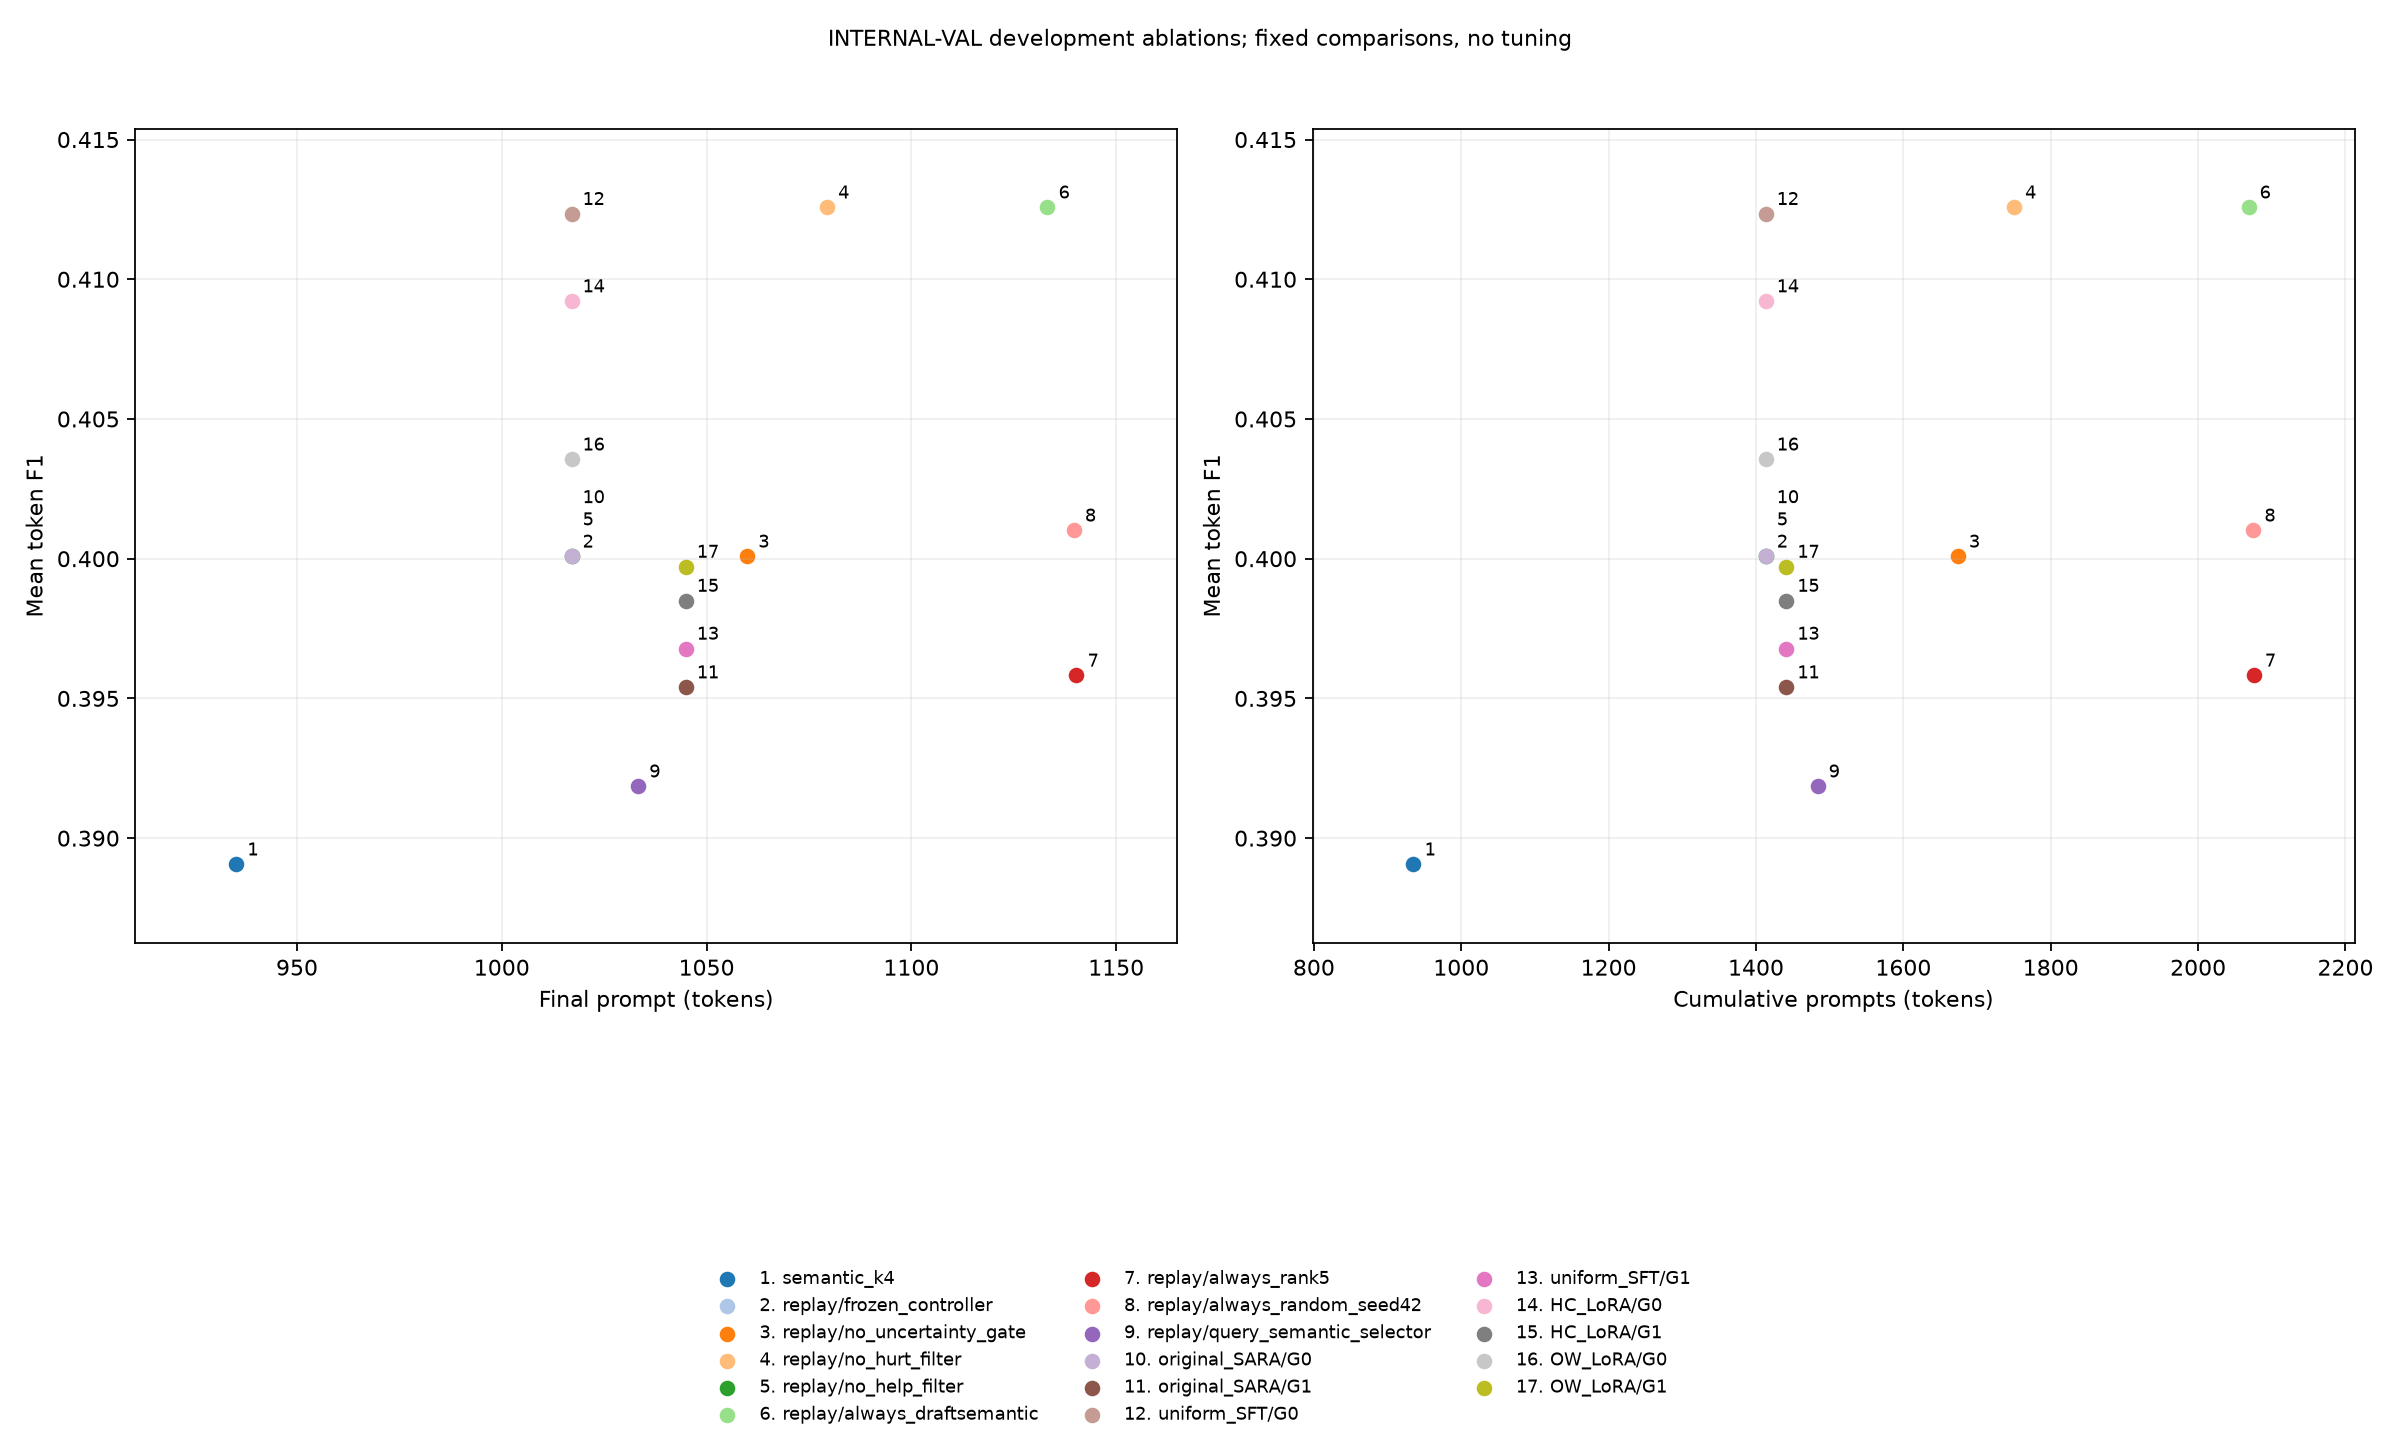

In [3]:
if RUN_FULL:
    if not globals().get('SMOKE_PASSED', False):
        raise RuntimeError('Run the smoke cell successfully first.')
    run('--full')
    display(pd.read_csv(OUTPUT / 'full/benchmark.csv'))
    display(pd.read_csv(OUTPUT / 'full/paired_paper_intervals.csv'))
    display(Image(filename=str(OUTPUT / 'full/quality_cost.png')))
else:
    print('Smoke complete. Set RUN_FULL=True in the first cell, then rerun it and this cell for the full evaluation.')
